# Можно ли доверять LLM в задачах классического машинного обучения


## 0. Настройки и источники

In [1]:
DEMO = False

In [2]:
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import analysis as an, autograde, bank, checks, llm, run_bank, typeE, provenance
from src import notebook_data as nd

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

P = an.paths(DEMO)                      
CFG = run_bank.load_experiment()        
SEED = CFG["seed"]               
N_BOOT = CFG["bootstrap_n"]            
LANG = CFG["languages"][0]             
SELECTED = CFG["hypotheses"]            
MODELS = llm.load_models()             
PRICING = an.load_pricing(P["pricing"])
TAG = an.demo_label(DEMO)            
DATA = nd.NotebookData(P, MODELS, demo=DEMO)
# Пять моделей экспортируются отдельно: исходные summary и рисунки не заменяются.
P['summary'] = P['results'] / 'summary_metrics_five_models.json'
P['figures'] = P['figures'] / 'five_models'

technical_review = json.loads((P['grading'] / 'parser_technical_review.json').read_text(encoding='utf-8')) if not DEMO else {}
d1_resolution = json.loads((P['grading'] / 'd1_technical_resolution.json').read_text(encoding='utf-8')) if not DEMO else {}
summary = {"demo": DEMO, "inputs": DATA.fingerprints(), "hypotheses_selected": SELECTED,
           "seed": SEED, "bootstrap_n": N_BOOT, "coverage": {}}
summary['d1_technical_resolution'] = d1_resolution
confirmation_path = P['grading'] / 'submission_confirmation.json'
summary['submission_confirmation'] = json.loads(confirmation_path.read_text()) if confirmation_path.exists() else {}
if DEMO:
    print("=" * 70 + "\nDEMO: mock-модели и случайные оценки. Это НЕ результаты эксперимента.\n" + "=" * 70)
print("Выбранные гипотезы:", SELECTED or "ещё не выбраны (config/experiment.json)")
print("Входные файлы:", *summary["inputs"], sep="\n  ")

summary["hypotheses"] = {}
tasks = bank.load_tasks(bank.BANK_PATH)
splitE = typeE.load_split()
hypothesis_specs = checks.parse_hypotheses_md((an.ROOT / "hypotheses.md").read_text())

Выбранные гипотезы: ['H1', 'H6', 'H9']
Входные файлы:
  results/cot_ru.jsonl
  results/d_exec.jsonl
  results/followup_doubt_ru.jsonl
  results/graded_auto.jsonl
  results/main_ru.jsonl
  results/typeE_llm.jsonl
  results/typeE_classical.csv
  results/typeE_metrics.csv
  grading/d1_technical_resolution.csv
  grading/key_DO_NOT_OPEN.csv
  grading/parser_spotcheck.csv
  grading/parser_technical_review.csv
  grading/sheet_r1.csv
  grading/sheet_r2.csv
  grading/submission_confirmation.json
  grading/d1_technical_resolution.json
  grading/parser_technical_review.json
  config/pricing.json
  config/experiment.json
  logs/calls.jsonl
  data/tasks.jsonl
  data/e_split.json
  config/models.json
  src/notebook_data.py
  results/korolev/main_ru.jsonl
  results/korolev/d_exec.jsonl
  results/korolev/cot_ru.jsonl
  results/korolev/followup_doubt_ru.jsonl
  results/korolev/typeE_llm.jsonl
  results/korolev/graded_auto.jsonl
  grading/korolev/sheet_r2.csv
  grading/korolev/sheet_r1.csv
  grading/kor

## Введение. Цель и гипотезы

Цель — измерить надёжность LLM на задачах классического ML. Основной банк — A/B/C/D/F;
E — отдельная классификация AI4I. H1, H6 и H9 являются  выбранными гипотезами.
Ниже дословно выводятся прогнозы и критерии из `hypotheses.md`, зафиксированного до прогонов.

In [3]:
for spec in hypothesis_specs:
    print(json.dumps(spec, ensure_ascii=False, indent=2))

{
  "ID": "H1",
  "Группа": "1 — рассуждение или запоминание",
  "Формулировка": "Изменённые числа. Точность на «учебниковых» задачах выше, чем на тех же задачах с изменёнными числами или условиями. Если разрыв большой — модель скорее «вспоминает», чем решает.",
  "Прогноз": "не подтвердится",
  "Обоснование прогноза": "задачи A1–A5 — простые вычисления по формуле (Байес, Джини, метрики, SVM, МНК), и сильные модели (DeepSeek-v4-pro, GigaChat-2-Max, YandexGPT Pro) скорее считают, чем вспоминают, поэтому решат обе версии (эффект потолка); падение при смене чисел, как в GSM-Symbolic (Mirzadeh et al., 2024), ожидаю в основном у маленькой qwen3:8b. При 5 парах × 4 модели = 20 наблюдений разрыв ≥ 20 п.п. с p < 0,05 требует ≥ 6 несогласованных пар — по объединённым моделям, скорее всего, не наберётся.",
  "Метрика": "точность на оригиналах A1–A5 минус точность на изменённых версиях F1–F5 (пары P1–P5) — по каждой модели и по всем 4 моделям вместе (20 пар).",
  "Критерий решения (тест, порог)":

## 1. Методика эксперимента

### 1.1. Исследуемые модели, параметры и промпт — таблица 1.1

Температура: 0,0001 для GigaChat и 0 для остальных. Seed=42 фиксирует разбиение и статистику;
Ollama получает seed=42+repeat, а облачные вызовы не получают общего seed.
DeepSeek: thinking disabled; qwen3:8b: think=false, num_ctx=8192.
`max_tokens` не задан.
Королёв ИИ К5 (`korolev-k5`) входит в основной состав пяти исследуемых моделей.
Протокол веб-ассистента может добавлять скрытый контекст; это разновременное дополнение,
а не новый одновременный прогон пяти API. Все расчёты ниже офлайн.

In [4]:
summary["bank"] = an.bank_summary(tasks)
summary["runs"] = DATA.runs(MODELS)
an.show(pd.DataFrame([{"model_key": k, **v} for k, v in summary["runs"]["models"].items()]),
        "Таблица 1.1: идентификаторы API, параметры и вызовы (без smoke/dev)", DEMO)
an.show(pd.DataFrame([{"experiment": k, **v} for k, v in summary["runs"]["calls_by_experiment"].items()]),
        "Вызовы по экспериментам: успешные ответы, ошибки и повторы", DEMO)

Таблица 1.1: идентификаторы API, параметры и вызовы (без smoke/dev)


,model_key,provider,model_requested,model_reported,params,effective_temperature,min_temperature,max_tokens,experiments,first_utc,last_utc,records,ok,errors,retried_requests,unresolved_requests,tokens_in,tokens_out,finish_reason_length,periods,ollama_base_url,local_vram_mb_max,local_model_size_mb_max
0,deepseek-v4-pro,openai_compat,[deepseek-v4-pro],[deepseek-v4-pro],[{'extra_body': {'thinking': {'type': 'disable...,[0.0],0.000,[None],"[cot, followup_doubt, main, typeE]",2026-10-15T00:39:12.717+00:00,2026-10-15T10:22:30.275+00:00,711,680,31,3,0,524055,190052,0,{'cot': {'first_utc': '2026-10-15T00:43:04.928...,NaN,NaN,NaN
1,gigachat-2-max,gigachat,[GigaChat-2-Max],[GigaChat-2-Max:2.0.30.01],[{}],[0.0001],0.000,[None],"[cot, followup_doubt, main, typeE]",2026-10-15T00:39:12.717+00:00,2026-10-15T03:45:11.965+00:00,675,675,0,0,0,76241,104429,0,{'cot': {'first_utc': '2026-10-15T00:43:04.928...,NaN,NaN,NaN
2,korolev-k5,korolev_web,[korolev-k5],[a13358d0-418a-4d64-b591-ad3fd9d9c01f],[{}],[0.0],0.000,[None],"[cot, followup_doubt, main, typeE]",2026-11-13T14:05:16.035+00:00,2026-11-13T23:23:00.528+00:00,680,679,1,1,0,3250247,263488,0,{'cot': {'first_utc': '2026-11-13T14:10:49.827...,NaN,NaN,NaN
3,qwen3-8b,ollama,[qwen3:8b],[qwen3:8b],"[{'options': {'num_ctx': 8192}, 'think': False}]",[0.0],0.000,[None],"[cot, followup_doubt, main, typeE]",2026-10-15T00:39:12.717+00:00,2026-10-15T03:51:24.280+00:00,673,673,0,0,0,650912,259340,0,{'cot': {'first_utc': '2026-10-15T00:43:04.928...,[http://localhost:11435],4983.300,4983.300
4,yandexgpt-pro-5.1,openai_compat,[gpt://b1gefd33pbo1ekddusqe/yandexgpt-5.1],[gpt://b1gefd33pbo1ekddusqe/yandexgpt-5.1],[{}],[0.0],0.000,[None],"[cot, followup_doubt, main, typeE]",2026-10-15T00:39:12.717+00:00,2026-10-15T03:26:35.912+00:00,676,676,0,0,0,481381,73189,0,{'cot': {'first_utc': '2026-10-15T00:43:04.928...,NaN,NaN,NaN


Вызовы по экспериментам: успешные ответы, ошибки и повторы


,experiment,first_utc,last_utc,records,ok,errors,retried_requests,unresolved_requests
0,cot,2026-10-15T00:43:04.928+00:00,2026-11-13T14:13:25.833+00:00,111,80,31,3,0
1,dev,2026-10-09T22:22:38.530+00:00,2026-10-14T18:28:36.484+00:00,110,110,0,0,0
2,followup_doubt,2026-10-15T01:22:28.418+00:00,2026-11-13T14:17:39.543+00:00,113,113,0,0,0
3,main,2026-10-15T00:39:12.717+00:00,2026-11-13T14:10:43.281+00:00,190,190,0,0,0
4,smoke,2026-10-09T17:52:54.153+00:00,2026-11-13T14:03:51.189+00:00,70,60,10,3,0
5,typeE,2026-10-15T03:19:10.759+00:00,2026-11-13T23:23:00.528+00:00,3001,3000,1,1,0


### 1.2. Состав банка задач

38 задач A/B/C/D/F × 5 моделей = 190 основных ответов.
Для E — 200 объектов × 3 числа примеров (0/5/20) × 5 моделей = 3000 ответов.
Из признаков E исключены идентификаторы и пять типов отказа.

In [5]:
print(f"Задач: {summary['bank']['n_tasks']}; своих: {summary['bank']['n_own']}")
an.show(summary["bank"]["tables"]["тип × тема"], "Таблица 1.2: тип × тема", DEMO, floatfmt="{:.0f}")
print("E:", {k: splitE[k] for k in ["n_rows", "n_failures_total", "natural_failure_rate", "n_test", "n_test_failures", "shot_failures"]})
print("Признаки E:", typeE.FEATURES)
print("Исключены:", typeE.ID_COLS + typeE.LEAK_COLS)

Задач: 38; своих: 20
Таблица 1.2: тип × тема


topic,type,bayes,clustering,ensembles,knn,linreg,logreg,metrics,pca,svm,trees,всего
0,A,1,0,0,1,1,1,1,1,1,1,8
1,B,1,1,1,1,1,1,1,1,0,0,8
2,C,1,1,1,0,0,1,0,1,1,0,6
3,D,0,1,1,1,1,0,0,1,1,0,6
4,F,1,1,1,1,1,1,1,1,1,1,10
5,всего,4,4,4,4,4,4,3,5,4,2,38


E: {'n_rows': 10000, 'n_failures_total': 339, 'natural_failure_rate': 0.0339, 'n_test': 200, 'n_test_failures': 40, 'shot_failures': {'5': 2, '20': 5}}
Признаки E: ['Type', 'Air temperature', 'Process temperature', 'Rotational speed', 'Torque', 'Tool wear']
Исключены: ['UDI', 'Product ID', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


### 1.3. Методы проверки 

A/F, вердикт B и метки E проверяются автоматически; обоснование B, выбор C и чек-лист D —
по двум листам. Правильность C/D усредняется по проверяющим и может быть 0,5.
Отказы при недостающих данных считаются правильными. 
Для точности используется кластерный бутстреп по `task_id`: при выборе задачи сохраняются
ответы всех моделей на неё. Это учитывает связанность ответов **разных моделей на одну задачу**.
Для H1 единица бутстрепа — пара P1–P5; для E — строка теста. B=1000, seed=42,
границы — перцентили 2,5% и 97,5%. Такой анализ не устраняет возможную зависимость разных задач.

In [6]:
manual = DATA.manual
if manual.empty:
    print("Листов ручной проверки нет: C и D пока без оценки .")
else:
    n_incomplete = int((~manual["complete"]).sum())
    print(f"Строк в листах: {len(manual)}; заполнены обоими полностью: {len(manual) - n_incomplete}")
    if n_incomplete:
        print(f"  ВНИМАНИЕ: {n_incomplete} строк заполнены не до конца — такие ответы C/D не входят в точность")
disagree = an.disagreements(manual) if not manual.empty else pd.DataFrame()
an.show(disagree, f"Расхождения проверяющих (всего {len(disagree)})", DEMO)

Строк в листах: 100; заполнены обоими полностью: 100
Расхождения проверяющих (всего 18)


,item_id,type,task_id,model_key,experiment,lang,column,r1,r2
0,C007,C,C5,gigachat-2-max,main,ru,score_0_2,1,0
1,C012,C,C4,deepseek-v4-pro,main,ru,score_0_2,2,1
2,C021,C,C3,deepseek-v4-pro,main,ru,score_0_2,1,2
3,D002,D,D4,deepseek-v4-pro,main,ru,d1_preprocessing_before_split,н/п,0
4,D003,D,D4,yandexgpt-pro-5.1,main,ru,d1_preprocessing_before_split,н/п,0
5,D004,D,D3,qwen3-8b,main,ru,d1_preprocessing_before_split,н/п,0
6,D005,D,D3,deepseek-v4-pro,main,ru,d1_preprocessing_before_split,н/п,0
7,D009,D,D5,deepseek-v4-pro,main,ru,d1_preprocessing_before_split,н/п,0
8,D012,D,D4,qwen3-8b,main,ru,d1_preprocessing_before_split,н/п,0
9,D013,D,D1,yandexgpt-pro-5.1,main,ru,d1_preprocessing_before_split,н/п,0


In [7]:
main, n_tech = DATA.answers('main', LANG)
HAVE_MAIN = not main.empty
ORDER = an.order_models(main["model_key"], MODELS) if HAVE_MAIN else []
main_common = nd.common_answers(main, ORDER)
COLORS = [an.model_color(m, MODELS) for m in ORDER]
summary["counts"] = {
    "main_answers": len(main),
    "main_tech_errors": n_tech,
    "main_ungraded": int(main["correct"].isna().sum()) if HAVE_MAIN else 0,
    "models": ORDER,
    "manual_rows": len(manual),
    "disagreements": len(disagree),
}
print(f"Основных ответов: {len(main)}; технических ошибок: {n_tech}")
review_status = DATA.review_status(ORDER)
an.show(review_status, 'Проверки B/C/D по каждой модели (один лист ≠ два)', DEMO)
summary['review_status'] = review_status

Основных ответов: 190; технических ошибок: 0
Проверки B/C/D по каждой модели (один лист ≠ два)


,model_key,answers_BCD,r1_filled,r2_filled,complete_two_raters,review_protocol
0,gigachat-2-max,20,20,20,20,два рабочих листа; происхождение см. grading/r...
1,yandexgpt-pro-5.1,20,20,20,20,два рабочих листа; происхождение см. grading/r...
2,deepseek-v4-pro,20,20,20,20,два рабочих листа; происхождение см. grading/r...
3,qwen3-8b,20,20,20,20,два рабочих листа; происхождение см. grading/r...
4,korolev-k5,20,20,20,20,два рабочих листа; происхождение см. grading/r...


#### Согласие проверяющих 


In [8]:
kappa = an.kappa_table(manual)
an.show(kappa, "Таблица 1.3: каппа по заполненным парам листов (Королёв пока без пар)", DEMO)
kappa_by_model = pd.concat([an.kappa_table(manual[manual['model_key'] == m]).assign(model_key=m) for m in ORDER], ignore_index=True)
an.show(kappa_by_model, 'Каппа отдельно по каждой модели; n_pairs=0 означает отсутствие второй проверки', DEMO)
summary['kappa_by_model'] = kappa_by_model
low = kappa[kappa["below_min"]] if not kappa.empty else kappa
summary["kappa"] = kappa
summary["kappa_below_min"] = low["type"].tolist() if len(low) else []
print('Проверяющие и полнота листов указаны в таблице статуса проверок.')

Таблица 1.3: каппа по заполненным парам листов (Королёв пока без пар)


,type,what,n_pairs,agreement,kappa,below_min
0,B,балл 0–2,40,1.000,1.000,False
1,C,балл 0–2,30,0.900,0.783,False
2,D,чек-лист (все пункты),180,0.917,0.847,False
3,D,чек-лист: масштабирование/препроцессинг до раз...,30,0.500,0.228,False
4,D,чек-лист: подбор гиперпараметров по тесту,30,1.000,1.000,False
5,D,чек-лист: оценка на обучающей выборке,30,1.000,1.000,False
6,D,чек-лист: accuracy при сильном дисбалансе,30,1.000,1.000,False
7,D,чек-лист: нет стратификации,30,1.000,1.000,False
8,D,чек-лист: не зафиксирован random_state,30,1.000,NaN,False
9,D,корректность метрики (ручная),7,1.000,NaN,False


Каппа отдельно по каждой модели; n_pairs=0 означает отсутствие второй проверки


,type,what,n_pairs,agreement,kappa,below_min,model_key
0,B,балл 0–2,8,1.000,1.000,False,gigachat-2-max
1,C,балл 0–2,6,0.833,0.000,True,gigachat-2-max
2,D,чек-лист (все пункты),36,0.889,0.810,False,gigachat-2-max
3,D,чек-лист: масштабирование/препроцессинг до раз...,6,0.333,0.077,False,gigachat-2-max
4,D,чек-лист: подбор гиперпараметров по тесту,6,1.000,1.000,False,gigachat-2-max
5,D,чек-лист: оценка на обучающей выборке,6,1.000,1.000,False,gigachat-2-max
6,D,чек-лист: accuracy при сильном дисбалансе,6,1.000,1.000,False,gigachat-2-max
7,D,чек-лист: нет стратификации,6,1.000,1.000,False,gigachat-2-max
8,D,чек-лист: не зафиксирован random_state,6,1.000,NaN,False,gigachat-2-max
9,D,корректность метрики (ручная),3,1.000,NaN,False,gigachat-2-max


Проверяющие и полнота листов указаны в таблице статуса проверок.


## 2. Результаты эксперимента

### 2.1. Точность моделей

`accuracy` учитывает все оценённые ответы, в том числе правильные ответы «нельзя определить».
`refusal_rate` включает такие ответы, а `accuracy_answered` исключает только необоснованные отказы
(`abstain`).
Основной сопоставимый рейтинг пяти моделей и график используют одинаковые 26 задач A/B/F.
Отдельно показана описательная точность на доступных оценках всего банка с числом пропусков.
У Королёва C/D пока без двух проверок: эти клетки пустые, а не нулевые.

In [9]:
if HAVE_MAIN:
    acc_model = an.acc_table(main_common, ["model_key"], N_BOOT, SEED).set_index("model_key").loc[ORDER].reset_index()
    acc_available = an.acc_table(main, ['model_key'], N_BOOT, SEED)
    acc_type = an.acc_table(main, ["type"], N_BOOT, SEED).sort_values("type")   
    acc_mt = an.acc_table(main, ["model_key", "type"], N_BOOT, SEED)
else:
    acc_model = acc_available = acc_type = acc_mt = pd.DataFrame()
an.show(acc_model, "Сопоставимая точность пяти моделей (общий A/B/F, RU)", DEMO)
an.show(acc_available, 'Весь банк: доступные оценки и пропуски; не рейтинг на одинаковых 38 задачах', DEMO)
summary['accuracy_available'] = acc_available
an.show(acc_type, "Точность по типам задач (все модели вместе)", DEMO)
an.show(acc_mt, "Точность «модель × тип»", DEMO)
summary["accuracy_by_model"] = acc_model
summary["accuracy_by_type"] = acc_type
summary["accuracy_by_model_type"] = acc_mt

Сопоставимая точность пяти моделей (общий A/B/F, RU)


,model_key,n,n_graded,n_ungraded,n_correct,accuracy,ci_low,ci_high,refusal_rate,n_abstain,accuracy_answered
0,gigachat-2-max,26,26,0,21.000,0.808,0.654,0.962,0.077,0,0.808
1,yandexgpt-pro-5.1,26,26,0,22.000,0.846,0.692,0.962,0.038,0,0.846
2,deepseek-v4-pro,26,26,0,26.000,1.000,1.000,1.000,0.115,0,1.000
3,qwen3-8b,26,26,0,19.000,0.731,0.538,0.885,0.115,0,0.731
4,korolev-k5,26,26,0,25.000,0.962,0.885,1.000,0.115,0,0.962


Весь банк: доступные оценки и пропуски; не рейтинг на одинаковых 38 задачах


,model_key,n,n_graded,n_ungraded,n_correct,accuracy,ci_low,ci_high,refusal_rate,n_abstain,accuracy_answered
0,gigachat-2-max,38,38,0,29.500,0.776,0.645,0.895,0.053,0,0.776
1,yandexgpt-pro-5.1,38,38,0,33.000,0.868,0.763,0.974,0.026,0,0.868
2,deepseek-v4-pro,38,38,0,37.000,0.974,0.921,1.000,0.079,0,0.974
3,qwen3-8b,38,38,0,29.000,0.763,0.632,0.895,0.079,0,0.763
4,korolev-k5,38,38,0,36.000,0.947,0.868,1.000,0.079,0,0.947


Точность по типам задач (все модели вместе)


,type,n,n_graded,n_ungraded,n_correct,accuracy,ci_low,ci_high,refusal_rate,n_abstain,accuracy_answered
0,A,40,40,0,36.000,0.900,0.800,0.975,0.000,0,0.900
1,B,40,40,0,38.000,0.950,0.875,1.000,0.000,0,0.950
2,C,30,30,0,28.500,0.950,0.850,1.000,0.000,0,0.950
3,D,30,30,0,23.000,0.767,0.433,0.967,0.000,0,0.767
4,F,50,50,0,39.000,0.780,0.660,0.900,0.240,0,0.780


Точность «модель × тип»


,model_key,type,n,n_graded,n_ungraded,n_correct,accuracy,ci_low,ci_high,refusal_rate,n_abstain,accuracy_answered
0,gigachat-2-max,A,8,8,0,7.000,0.875,0.625,1.000,0.000,0,0.875
1,gigachat-2-max,B,8,8,0,8.000,1.000,1.000,1.000,0.000,0,1.000
2,gigachat-2-max,C,6,6,0,5.500,0.917,0.750,1.000,0.000,0,0.917
3,gigachat-2-max,D,6,6,0,3.000,0.500,0.167,0.833,0.000,0,0.500
4,gigachat-2-max,F,10,10,0,6.000,0.600,0.300,0.900,0.200,0,0.600
5,yandexgpt-pro-5.1,A,8,8,0,7.000,0.875,0.625,1.000,0.000,0,0.875
6,yandexgpt-pro-5.1,B,8,8,0,8.000,1.000,1.000,1.000,0.000,0,1.000
7,yandexgpt-pro-5.1,C,6,6,0,6.000,1.000,1.000,1.000,0.000,0,1.000
8,yandexgpt-pro-5.1,D,6,6,0,5.000,0.833,0.500,1.000,0.000,0,0.833
9,yandexgpt-pro-5.1,F,10,10,0,7.000,0.700,0.400,1.000,0.100,0,0.700


In [10]:
scores = nd.rubric_scores(manual, ORDER)
an.show(scores, 'Баллы B/C: r1 и r2 отдельно; mean_score только для двух проверок', DEMO)
summary["rubric_scores"] = scores

Баллы B/C: r1 и r2 отдельно; mean_score только для двух проверок


,model_key,type,n,n_two_raters,mean_score,r1_mean,r2_mean
0,gigachat-2-max,B,8,8,1.750,1.750,1.750
1,gigachat-2-max,C,6,6,0.917,1.000,0.833
2,yandexgpt-pro-5.1,B,8,8,1.750,1.750,1.750
3,yandexgpt-pro-5.1,C,6,6,1.000,1.000,1.000
4,deepseek-v4-pro,B,8,8,1.750,1.750,1.750
5,deepseek-v4-pro,C,6,6,1.500,1.500,1.500
6,qwen3-8b,B,8,8,1.125,1.125,1.125
7,qwen3-8b,C,6,6,1.000,1.000,1.000
8,korolev-k5,B,8,8,2.000,2.000,2.000
9,korolev-k5,C,6,6,1.667,1.667,1.667


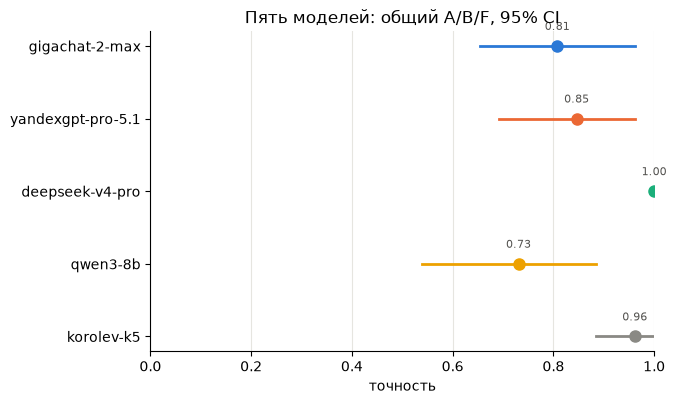

In [11]:
if HAVE_MAIN:
    fig = an.plot_share_ci(acc_model, "model_key", "accuracy", "ci_low", "ci_high",
                           TAG + "Пять моделей: общий A/B/F, 95% CI", "точность", colors=COLORS)
    fig.axes[0].set_xlim(0, 1)
    an.save_fig(fig, "accuracy_ci", P["figures"], DEMO)
    plt.show()

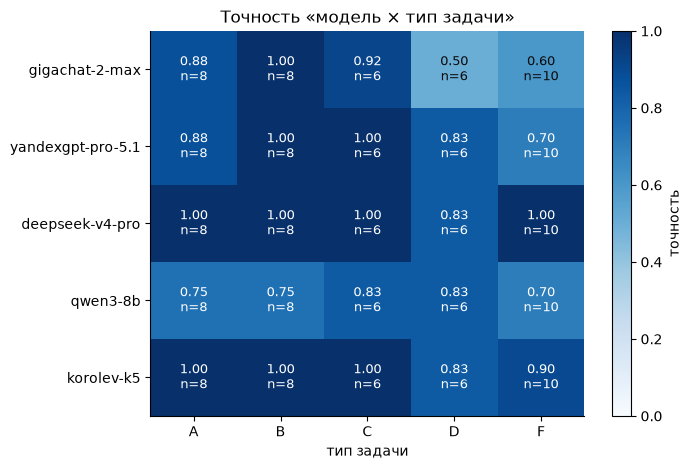

In [12]:
if HAVE_MAIN:
    heat = acc_mt.pivot(index="model_key", columns="type", values="accuracy").reindex(index=ORDER, columns=an.BANK_TYPES)
    heat_n = acc_mt.pivot(index="model_key", columns="type", values="n_graded").reindex(index=ORDER, columns=an.BANK_TYPES)
    fig, ax = plt.subplots(figsize=(7, 0.7 * len(ORDER) + 1.5))
    im = ax.imshow(heat.to_numpy(dtype=float), cmap="Blues", vmin=0, vmax=1, aspect="auto")
    for i in range(heat.shape[0]):
        for j in range(heat.shape[1]):
            v, n = heat.iat[i, j], heat_n.iat[i, j]
            if pd.isna(v):
                ax.text(j, i, 'нет двух\nпроверок', ha='center', va='center', fontsize=8)
            if pd.notna(v):
                ax.text(j, i, f"{v:.2f}\nn={int(n)}", ha="center", va="center", fontsize=9,
                        color="white" if v > 0.6 else "#0b0b0b")
    ax.set_xticks(range(len(an.BANK_TYPES)), an.BANK_TYPES)
    ax.set_yticks(range(len(ORDER)), ORDER)
    ax.set_xlabel("тип задачи")
    ax.set_title(TAG + "Точность «модель × тип задачи»")
    fig.colorbar(im, ax=ax, label="точность")
    an.save_fig(fig, "heatmap_model_type", P["figures"], DEMO)
    plt.show()

#### Результаты типа E

In [13]:
typeE_tab = DATA.type_e_table()
cols = ["source", "model", "shots", "train_set", "eval_set", "n_eval", "coverage", "f1_failure",
        "balanced_accuracy", "accuracy", "f1_failure_sd", "balanced_accuracy_sd", "f1_failure_answered",
        "balanced_accuracy_answered", "complete"]
an.show(typeE_tab[cols], "Тип E: метрики LLM и классических моделей", DEMO)
summary["typeE"] = typeE_tab

Тип E: метрики LLM и классических моделей


,source,model,shots,train_set,eval_set,n_eval,coverage,f1_failure,balanced_accuracy,accuracy,f1_failure_sd,balanced_accuracy_sd,f1_failure_answered,balanced_accuracy_answered,complete
0,llm,deepseek-v4-pro,0,none,test,200,1.000,0.315,0.566,0.695,NaN,NaN,0.315,0.566,True
1,llm,deepseek-v4-pro,5,prompt,test,200,1.000,0.457,0.666,0.750,NaN,NaN,0.457,0.666,True
2,llm,deepseek-v4-pro,20,prompt,test,200,1.000,0.566,0.762,0.770,NaN,NaN,0.566,0.762,True
3,llm,gigachat-2-max,0,none,test,200,0.995,0.283,0.509,0.545,NaN,NaN,0.286,0.511,True
4,llm,gigachat-2-max,5,prompt,test,200,1.000,0.556,0.734,0.800,NaN,NaN,0.556,0.734,True
5,llm,gigachat-2-max,20,prompt,test,200,1.000,0.632,0.762,0.860,NaN,NaN,0.632,0.762,True
6,llm,qwen3-8b,0,none,test,200,1.000,0.356,0.550,0.295,NaN,NaN,0.356,0.550,True
7,llm,qwen3-8b,5,prompt,test,200,1.000,0.396,0.622,0.665,NaN,NaN,0.396,0.622,True
8,llm,qwen3-8b,20,prompt,test,200,1.000,0.424,0.637,0.810,NaN,NaN,0.424,0.637,True
9,llm,yandexgpt-pro-5.1,0,none,test,200,1.000,0.333,0.528,0.380,NaN,NaN,0.333,0.528,True


In [14]:
splitE = typeE.load_split()
predsE_ci = DATA.type_e_predictions(splitE, LANG)
cfgE = CFG["typeE"]
covE = an.coverage_table(predsE_ci, {m: cfgE["n_test"] * len(cfgE["shots"]) for m in ORDER})
an.show(covE, "Тип E: полнота прогона по моделям", DEMO)
if len(covE) and not covE["complete"].all():
    print("ВНИМАНИЕ: прогон E неполный у:", ", ".join(covE.loc[~covE["complete"], "model_key"]))
summary["coverage"]["typeE"] = covE
if predsE_ci.empty:
    typeE_ci = pd.DataFrame()
    print("Нет ответов LLM типа E на текущем тесте (results/typeE_llm.jsonl).")
else:
    lrE = an.logreg_rows(an.logreg_predictions(splitE, SEED), predsE_ci)
    typeE_ci = an.typeE_ci_table(pd.concat([predsE_ci, lrE]), N_BOOT, SEED).sort_values(["shots", "model_key"])
an.show(typeE_ci, "Тип E: F1 «отказа» и balanced accuracy с 95% CI", DEMO)
summary["typeE_ci"] = typeE_ci

Тип E: полнота прогона по моделям


,model_key,n_expected,n_got,complete
0,gigachat-2-max,600,600,True
1,yandexgpt-pro-5.1,600,600,True
2,deepseek-v4-pro,600,600,True
3,qwen3-8b,600,600,True
4,korolev-k5,600,600,True


Тип E: F1 «отказа» и balanced accuracy с 95% CI


,model_key,shots,n_rows,f1_failure,f1_ci_low,f1_ci_high,balanced_accuracy,ba_ci_low,ba_ci_high
9,deepseek-v4-pro,0,200,0.315,0.184,0.440,0.566,0.483,0.649
0,gigachat-2-max,0,200,0.283,0.174,0.384,0.509,0.415,0.602
12,korolev-k5,0,200,0.319,0.217,0.413,0.534,0.446,0.618
6,qwen3-8b,0,200,0.356,0.272,0.431,0.550,0.511,0.582
3,yandexgpt-pro-5.1,0,200,0.333,0.244,0.417,0.528,0.455,0.599
16,LogisticRegression,5,200,0.281,0.136,0.426,0.572,0.514,0.638
10,deepseek-v4-pro,5,200,0.457,0.329,0.572,0.666,0.584,0.754
1,gigachat-2-max,5,200,0.556,0.421,0.667,0.734,0.650,0.811
13,korolev-k5,5,200,0.512,0.381,0.630,0.700,0.619,0.779
7,qwen3-8b,5,200,0.396,0.274,0.512,0.622,0.536,0.709


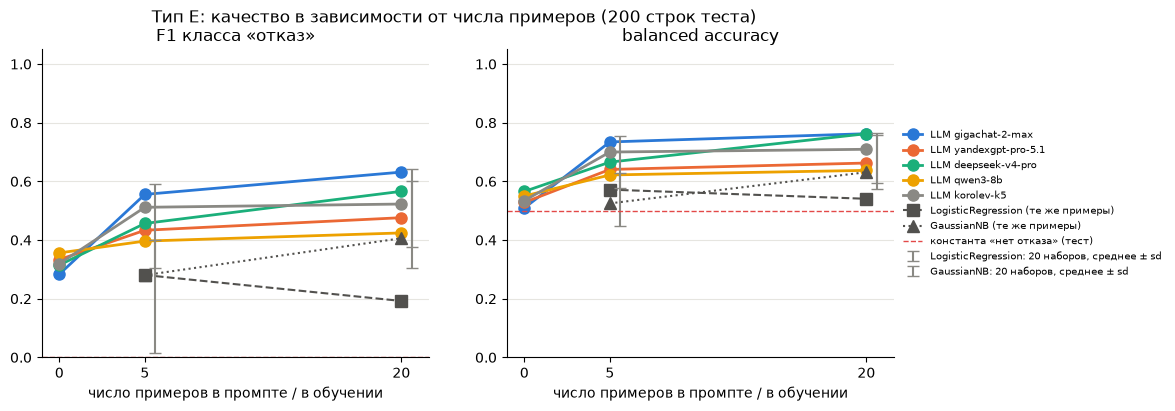

Константа «нет отказа» на всём датасете: accuracy = 0.9661 (отказов 339 из 10000)


In [15]:
llmE = typeE_tab[typeE_tab["source"] == "llm"]
cls = typeE_tab[typeE_tab["source"] == "classical"]
if llmE.empty:
    print("Ответов LLM типа E нет — рисунок не строится.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
    for ax, metric, name in [(axes[0], "f1_failure", "F1 класса «отказ»"), (axes[1], "balanced_accuracy", "balanced accuracy")]:
        for m in an.order_models(llmE["model"], MODELS):
            g = llmE[llmE["model"] == m].sort_values("shots")
            ax.plot(g["shots"], g[metric], "o-", lw=2, ms=8, color=an.model_color(m, MODELS), label=f"LLM {m}")
        for model, style in [("LogisticRegression", "s--"), ("GaussianNB", "^:")]:
            fx = cls[(cls["model"] == model) & (cls["train_set"] == "fixed")].sort_values("shots")
            rs = cls[(cls["model"] == model) & (cls["train_set"] == "resample")].sort_values("shots")
            ax.plot(fx["shots"], fx[metric], style, color="#52514e", ms=8, label=f"{model} (те же примеры)")
            ax.errorbar(rs["shots"] + 0.6, rs[metric], yerr=rs[f"{metric}_sd"], fmt="none", ecolor="#8a8984",
                        capsize=4, label=f"{model}: 20 наборов, среднее ± sd")
        const = cls[(cls["model"] == "Dummy(most_frequent)") & (cls["eval_set"] == "test")][metric]
        if len(const):
            ax.axhline(const.iloc[0], color="#e34948", ls="--", lw=1, label="константа «нет отказа» (тест)")
        ax.set_title(name)
        ax.set_xticks([0, 5, 20])
        ax.set_xlabel("число примеров в промпте / в обучении")
        ax.set_ylim(0, 1.05)
        ax.grid(axis="y", color="#e6e5e0")
    axes[1].legend(fontsize=7, frameon=False, loc="center left", bbox_to_anchor=(1, 0.5))
    fig.suptitle(TAG + "Тип E: качество в зависимости от числа примеров (200 строк теста)")
    an.save_fig(fig, "typeE_shots", P["figures"], DEMO)
    plt.show()
full = cls[cls["eval_set"] == "full"]
if len(full):
    print(f"Константа «нет отказа» на всём датасете: accuracy = {full['accuracy'].iloc[0]:.4f} "
          f"(отказов {int(full['n_eval_failures'].iloc[0])} из {int(full['n_eval'].iloc[0])})")

### 2.2. Точный тест Макнемара

Для десяти пар пяти моделей применяется поправка Холма. Основное сравнение использует
общие 26 автоматически проверяемых задач A/B/F, одинаковые для всех пяти.
Значения 0,5 и отсутствующие проверки C/D в бинарный тест не входят.

In [16]:
mcn = an.mcnemar_pairs(main_common, ORDER) if HAVE_MAIN else pd.DataFrame()
an.show(mcn, "Макнемар для пар моделей (+ поправка Холма)", DEMO, floatfmt="{:.4f}")
summary["mcnemar_models"] = mcn

Макнемар для пар моделей (+ поправка Холма)


,model_a,model_b,n,both_correct,only_first,only_second,both_wrong,acc_first,acc_second,p_value,p_holm
0,gigachat-2-max,yandexgpt-pro-5.1,26,18,3,4,1,0.8077,0.8462,1.0000,1.0000
1,gigachat-2-max,deepseek-v4-pro,26,21,0,5,0,0.8077,1.0000,0.0625,0.5000
2,gigachat-2-max,qwen3-8b,26,17,4,2,3,0.8077,0.7308,0.6875,1.0000
3,gigachat-2-max,korolev-k5,26,20,1,5,0,0.8077,0.9615,0.2188,1.0000
4,yandexgpt-pro-5.1,deepseek-v4-pro,26,22,0,4,0,0.8462,1.0000,0.1250,0.8750
5,yandexgpt-pro-5.1,qwen3-8b,26,16,6,3,1,0.8462,0.7308,0.5078,1.0000
6,yandexgpt-pro-5.1,korolev-k5,26,22,0,3,1,0.8462,0.9615,0.2500,1.0000
7,deepseek-v4-pro,qwen3-8b,26,19,7,0,0,1.0000,0.7308,0.0156,0.1562
8,deepseek-v4-pro,korolev-k5,26,25,1,0,0,1.0000,0.9615,1.0000,1.0000
9,qwen3-8b,korolev-k5,26,19,0,6,1,0.7308,0.9615,0.0312,0.2812


### 2.3. Стоимость, задержка и эффективность 

Официальные тарифы на 25.10.2026, курс 84,905 руб./USD. Стоимость правильного ответа равна
общей стоимости / сумме `correct`.
Для qwen3 нулевая величина означает отсутствие тарифа API, а не нулевые аппаратные затраты.
Цена Королёва неизвестна (NaN), не равна нулю. Ресурсы считаются по всем 38 ответам
каждой модели; стоимость правильного ответа сравнивается на общем A/B/F-поднаборе.

In [17]:
resource_table = nd.resources(main, PRICING, MODELS)
an.show(resource_table, 'Ресурсы всех основных ответов пяти моделей', DEMO)
summary['resources_main'] = resource_table
cost = an.cost_table(main_common, PRICING, MODELS, N_BOOT, SEED).set_index("model_key").loc[ORDER].reset_index() \
    if HAVE_MAIN else pd.DataFrame()
an.show(cost, "Стоимость и качество на общем A/B/F пяти моделей", DEMO, floatfmt="{:.4f}")
summary["cost"] = cost
summary["pricing"] = {"verified_by_human": PRICING.get("verified_by_human"), "date_checked": PRICING.get("date_checked"),
                      "usd_rub": PRICING.get("usd_rub", {}).get("rate")}
if len(llmE):
    e_cost = llmE.groupby("model")[["tokens_in_sum", "tokens_out_sum"]].sum()
    e_cost = e_cost.loc[an.order_models(e_cost.index, MODELS)].reset_index()  
    prices = [an.price_for(m, PRICING, MODELS) for m in e_cost["model"]]
    e_cost["cost_rub_total"] = [np.nan if p is None else ti * p[0] / 1e6 + to * p[1] / 1e6
                                for p, ti, to in zip(prices, e_cost["tokens_in_sum"], e_cost["tokens_out_sum"])]
else:
    e_cost = pd.DataFrame()
an.show(e_cost, "Тип E: токены и стоимость всего прогона", DEMO, floatfmt="{:.2f}")
summary["cost_typeE"] = e_cost

Ресурсы всех основных ответов пяти моделей


,model_key,n_answers,latency_s_mean,tokens_in_mean,tokens_in_full_mean,tokens_out_mean,cost_rub_total
0,gigachat-2-max,38,5.795,167.947,275.921,344.000,12.645
1,yandexgpt-pro-5.1,38,2.525,243.737,243.737,319.395,17.119
2,deepseek-v4-pro,38,17.089,303.868,303.868,344.000,5.689
3,qwen3-8b,38,3.470,361.632,361.632,419.000,0.000
4,korolev-k5,38,7.776,4238.184,4238.184,555.474,NaN


Стоимость и качество на общем A/B/F пяти моделей


,model_key,local,n,accuracy,n_correct,latency_s_mean,latency_s_median,tokens_in_mean,tokens_out_mean,tokens_in_full_mean,cost_rub_total,cost_rub_per_task,rub_per_correct,rub_per_correct_ci_low,rub_per_correct_ci_high
0,gigachat-2-max,False,26,0.8077,21.0000,6.2723,5.6245,170.5000,374.1538,274.7692,9.2046,0.3540,0.4383,0.3053,0.6439
1,yandexgpt-pro-5.1,False,26,0.8462,22.0000,2.5370,2.2355,241.9231,339.8846,241.9231,12.1016,0.4654,0.5501,0.4289,0.6959
2,deepseek-v4-pro,False,26,1.0000,26.0000,16.8418,13.8795,298.5769,333.5000,298.5769,3.7854,0.1456,0.1456,0.1083,0.2110
3,qwen3-8b,True,26,0.7308,19.0000,3.5992,3.0920,357.6154,434.3462,357.6154,0.0000,0.0000,0.0000,0.0000,0.0000
4,korolev-k5,False,26,0.9615,25.0000,7.9713,6.4605,4237.6154,588.3462,4237.6154,NaN,NaN,NaN,NaN,NaN


Тип E: токены и стоимость всего прогона


,model,tokens_in_sum,tokens_out_sum,cost_rub_total
0,gigachat-2-max,57225,76643,87.01
1,yandexgpt-pro-5.1,455258,48472,402.98
2,deepseek-v4-pro,491000,158715,108.39
3,qwen3-8b,617658,228148,0.00
4,korolev-k5,2900657,213460,NaN


In [18]:
mem = an.local_memory(P["log"], set(main["call_id"])) if HAVE_MAIN else pd.DataFrame()
an.show(mem, "Память локальной модели (МБ)", DEMO, floatfmt="{:.0f}")
manifest = json.loads(P["manifest"].read_text(encoding="utf-8")) if P["manifest"].exists() else {}
server = manifest.get("ollama_server", {})
if server:
    print("Сервер локальной модели (run_manifest.json → ollama_server):")
    print(json.dumps(server, ensure_ascii=False, indent=1)[:1500])
summary["local_model"] = {"memory": mem, "server": server}

Память локальной модели (МБ)


,model_key,n_calls,local_vram_mb_max,local_model_size_mb_max,local_mem_mb_max,ollama_base_url
0,qwen3-8b,38,4983,4983,NaN,http://localhost:11435


Сервер локальной модели (run_manifest.json → ollama_server):
{
 "hostname": "DESKTOP-GM9R4PJ",
 "os": "Майкрософт Windows 10 Pro 10.0.19045",
 "cpu": "AMD Ryzen Threadripper 3970X 32-Core Processor",
 "cpu_threads": 64,
 "ram_modules": [
  "8 GB 2133 MHz",
  "8 GB 2133 MHz",
  "8 GB 2133 MHz",
  "8 GB 2133 MHz"
 ],
 "gpu": [
  "NVIDIA GeForce RTX 3090, 24576 MiB, 591.74"
 ],
 "ram_gb": 31.9,
 "models": [
  "qwen3:8b 500a1f067a9f"
 ],
 "ollama_version": "0.40.2",
 "ollama_base_url": "http://localhost:11435",
 "ssh_host": "gpu",
 "collected_utc": "2026-10-15T01:29:50+00:00",
 "note": "Со слов владельца, оперативная память ПК сбоит (возможны падения и перезагрузки). Ollama запускается внутри ssh-сессии (scripts/gpu_ollama.sh, туннель localhost:11435). Каждый вызов сразу пишется в logs/calls.jsonl, после падения прогон продолжается из кэша; ответы с ошибкой соединения не считаются ответами модели."
}


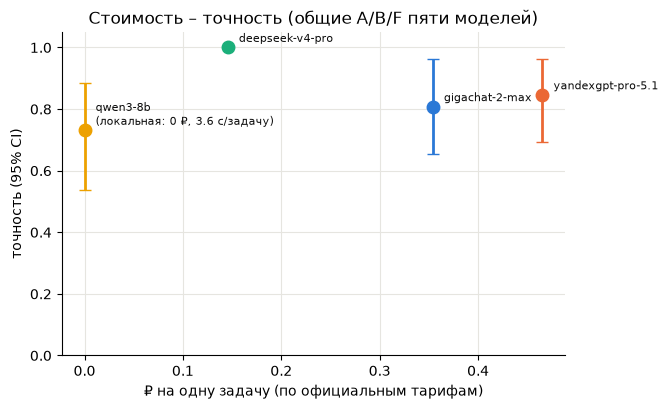

In [19]:
if HAVE_MAIN:
    fig, ax = plt.subplots(figsize=(6.5, 4.2))
    for r, c in zip(cost.itertuples(), COLORS):
        a = acc_model.set_index("model_key").loc[r.model_key]
        x = 0 if r.local else r.cost_rub_per_task
        ax.errorbar(x, a["accuracy"], yerr=[[a["accuracy"] - a["ci_low"]], [a["ci_high"] - a["accuracy"]]],
                    fmt="o", color=c, ms=9, capsize=4, lw=2)
        label = r.model_key + (f"\n(локальная: 0 ₽, {r.latency_s_mean:.1f} с/задачу)" if r.local else "")
        ax.annotate(label, (x, a["accuracy"]), textcoords="offset points", xytext=(8, 4), fontsize=8, color="#0b0b0b")
    ax.set_xlabel("₽ на одну задачу (по официальным тарифам)")
    ax.set_ylabel("точность (95% CI)")
    ax.set_ylim(0, 1.05)
    ax.set_title(TAG + "Стоимость – точность (общие A/B/F пяти моделей)")
    ax.grid(color="#e6e5e0")
    ax.set_axisbelow(True)
    an.save_fig(fig, "cost_accuracy", P["figures"], DEMO)
    plt.show()

In [20]:
an.show(llmE[["model", "shots", "latency_s_mean", "tokens_in_sum", "tokens_out_sum"]],
        "E: задержка и токены по числу примеров", DEMO)

E: задержка и токены по числу примеров


,model,shots,latency_s_mean,tokens_in_sum,tokens_out_sum
0,deepseek-v4-pro,0,4.656,52600,38816
1,deepseek-v4-pro,5,5.441,120200,59398
2,deepseek-v4-pro,20,5.512,318200,60501
3,gigachat-2-max,0,5.110,16034,59305
4,gigachat-2-max,5,0.930,17256,5781
5,gigachat-2-max,20,1.473,23935,11557
6,qwen3-8b,0,1.641,63686,38631
7,qwen3-8b,5,3.296,149886,80000
8,qwen3-8b,20,4.609,404086,109517
9,yandexgpt-pro-5.1,0,1.293,42686,14519


### 2.4. Код scikit-learn и калибровка уверенности


D: запуск, корректность и методологические ошибки (пять моделей)


,model_key,n_programs,pass_at_1,n_pass_unknown,correct,n_correct_graded,method_error_any,n_method_graded,pass_at_1_ci_low,pass_at_1_ci_high,correct_ci_low,correct_ci_high,method_error_any_ci_low,method_error_any_ci_high,d1_preprocessing_before_split,d2_tuning_on_test,d3_eval_on_train,d4_accuracy_imbalance,d5_no_stratify,d6_no_random_state
0,gigachat-2-max,6,0.667,0,0.500,6,0.667,6,0.333,1.000,0.167,0.833,0.333,1.000,0.000,0.000,0.000,0.000,1.000,0.000
1,yandexgpt-pro-5.1,6,1.000,0,0.833,6,0.667,6,1.000,1.000,0.500,1.000,0.333,1.000,0.000,0.000,0.000,0.000,1.000,0.000
2,deepseek-v4-pro,6,1.000,0,0.833,6,0.000,6,1.000,1.000,0.500,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
3,qwen3-8b,6,1.000,0,0.833,6,0.667,6,1.000,1.000,0.500,1.000,0.333,1.000,0.000,0.000,0.000,0.000,1.000,0.000
4,korolev-k5,6,1.000,0,0.833,6,0.500,6,1.000,1.000,0.500,1.000,0.167,0.833,0.200,0.000,0.000,0.000,0.750,0.000
5,все модели,30,0.933,0,0.767,30,0.500,30,0.867,1.000,0.433,0.967,0.233,0.767,0.040,0.000,0.000,0.000,0.750,0.000


D: сохранённая автоматическая сверка метрики, не замена ручному ревью


,model_key,n,n_auto_graded,metric_correct_auto
0,deepseek-v4-pro,6,6,0.833
1,gigachat-2-max,6,6,0.500
2,korolev-k5,6,6,0.833
3,qwen3-8b,6,6,0.833
4,yandexgpt-pro-5.1,6,6,0.833


ECE: общий A/B/F пяти моделей


,model_key,n,n_no_confidence,mean_confidence,accuracy,gap,gap_ci_low,gap_ci_high,ece,ece_ci_low,ece_ci_high,n_distinct_confidence
0,gigachat-2-max,23,3,0.991,0.826,0.165,0.030,0.339,0.165,0.030,0.339,2
1,yandexgpt-pro-5.1,26,0,0.994,0.846,0.148,0.033,0.294,0.148,0.033,0.294,3
2,deepseek-v4-pro,26,0,0.992,1.000,-0.008,-0.016,-0.002,0.008,0.002,0.016,3
3,qwen3-8b,26,0,0.998,0.731,0.267,0.107,0.460,0.267,0.107,0.460,2
4,korolev-k5,1,25,0.999,1.000,-0.001,-0.001,-0.001,0.001,0.001,0.001,1


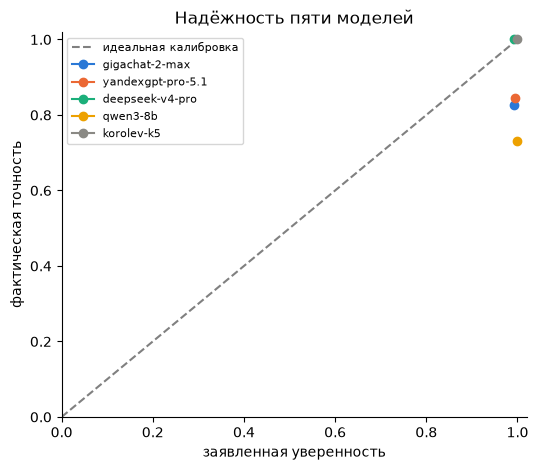

In [21]:
type_d = an.typeD_table(main, N_BOOT, SEED)
an.show(type_d, 'D: запуск, корректность и методологические ошибки (пять моделей)', DEMO)
summary['typeD'] = type_d
d_auto = main[main['type'] == 'D'].groupby('model_key').agg(n=('call_id', 'size'), n_auto_graded=('metric_ok_auto', 'count'), metric_correct_auto=('metric_ok_auto', 'mean')).reset_index()
an.show(d_auto, 'D: сохранённая автоматическая сверка метрики, не замена ручному ревью', DEMO)
summary['typeD_auto'] = d_auto
calibration = an.calibration_table(main_common, N_BOOT, SEED)
an.show(calibration, 'ECE: общий A/B/F пяти моделей', DEMO)
summary['calibration'] = calibration
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], '--', color='grey', label='идеальная калибровка')
for model in ORDER:
    g = main_common[(main_common['model_key'] == model) & main_common['confidence'].notna()]
    _, bins = an.ece(g['confidence'].to_numpy(float), g['correct'].to_numpy(float))
    bins = bins[bins['n'] > 0]
    ax.plot(bins['mean_confidence'], bins['accuracy'], 'o-', label=model, color=an.model_color(model, MODELS))
ax.set(xlabel='заявленная уверенность', ylabel='фактическая точность', title='Надёжность пяти моделей', xlim=(0, 1.02), ylim=(0, 1.02))
ax.legend(fontsize=8)
an.save_fig(fig, 'H10_reliability', P['figures'], DEMO)
plt.show()

## 3. Проверка гипотез исследования

### 3.1. Изменение числовых данных (H1) 


H1: оригинал vs изменённая версия (CI разницы — бутстреп пар)


,model_key,n_pairs,acc_original,acc_original_ci_low,acc_original_ci_high,acc_modified,acc_modified_ci_low,acc_modified_ci_high,diff_original_minus_modified,diff_ci_low,diff_ci_high,only_original_correct,only_modified_correct,mcnemar_p
0,gigachat-2-max,5,0.800,0.400,1.000,0.600,0.200,1.000,0.200,0.000,0.600,1,0,1.000
1,yandexgpt-pro-5.1,5,1.000,1.000,1.000,1.000,1.000,1.000,0.000,0.000,0.000,0,0,1.000
2,deepseek-v4-pro,5,1.000,1.000,1.000,1.000,1.000,1.000,0.000,0.000,0.000,0,0,1.000
3,qwen3-8b,5,0.600,0.200,1.000,0.800,0.400,1.000,-0.200,-0.600,0.000,0,1,1.000
4,korolev-k5,5,1.000,1.000,1.000,1.000,1.000,1.000,0.000,0.000,0.000,0,0,1.000
5,все,25,0.880,0.720,1.000,0.880,0.720,1.000,0.000,0.000,0.000,1,1,1.000


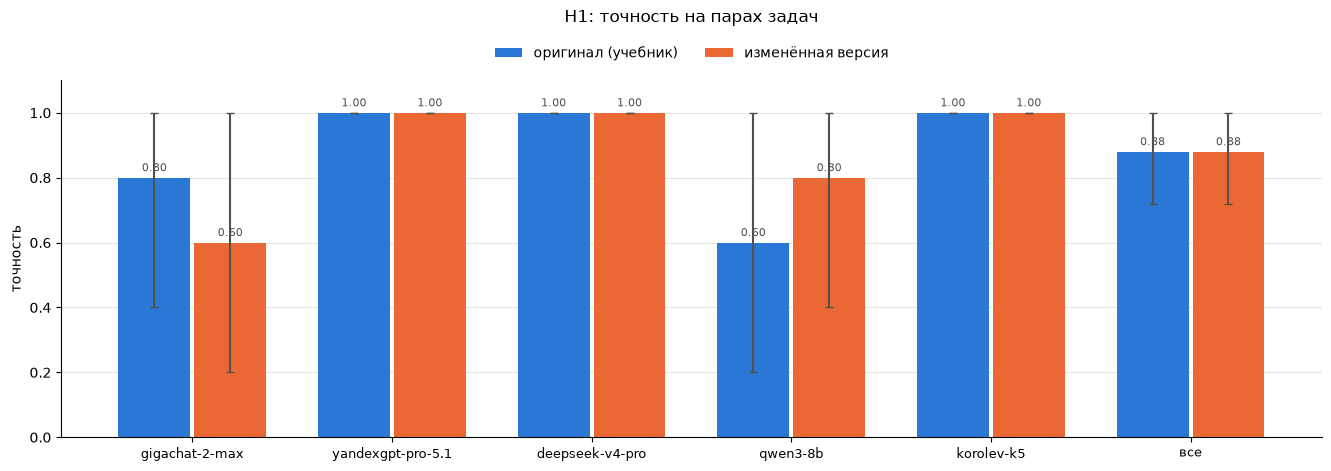

In [22]:
h1 = an.h1_pairs(main) if HAVE_MAIN else pd.DataFrame()
if h1.empty:
    print("Нет пар оригинал ↔ изменённая версия с ответами (нужны заполненные F1–F5 и main).")
else:
    h1_tab = an.name_conditions(an.compare_conditions(h1, "model_key", N_BOOT, SEED, cluster="pair_id"),
                                "original", "modified")
    an.show(h1_tab, "H1: оригинал vs изменённая версия (CI разницы — бутстреп пар)", DEMO)
    fig = an.plot_two_conditions(h1_tab, "model_key", "acc_original", "acc_modified", "оригинал (учебник)",
                                 "изменённая версия", TAG + "H1: точность на парах задач")
    an.save_fig(fig, "H1_original_vs_modified", P["figures"], DEMO)
    plt.show()
    summary["hypotheses"]["H1"] = {"table": h1_tab}

### 3.2. Пошаговое рассуждение (H6) 

Обычный промпт и CoT-промпт сравниваются для пяти исследуемых моделей.
Полный критерий из `hypotheses.md` включает опровержение при ΔA ≤ 0 **или** росте токенов менее 2×.

H6: полнота прогона cot по моделям (ответы без техошибок)


,model_key,n_expected,n_got,complete
0,gigachat-2-max,16,16,True
1,yandexgpt-pro-5.1,16,16,True
2,deepseek-v4-pro,16,16,True
3,qwen3-8b,16,16,True
4,korolev-k5,16,16,True


H6: точность A/B отдельно для каждой модели, включая Королёва


,group,n_pairs,acc_cot,acc_cot_ci_low,acc_cot_ci_high,acc_main,acc_main_ci_low,acc_main_ci_high,diff_cot_minus_main,diff_ci_low,diff_ci_high,only_cot_correct,only_main_correct,mcnemar_p
0,gigachat-2-max: A,8,0.875,0.625,1.000,0.875,0.625,1.000,0.000,0.000,0.000,0,0,1.000
1,gigachat-2-max: B,8,1.000,1.000,1.000,1.000,1.000,1.000,0.000,0.000,0.000,0,0,1.000
2,yandexgpt-pro-5.1: A,8,0.875,0.625,1.000,0.875,0.625,1.000,0.000,-0.375,0.250,1,1,1.000
3,yandexgpt-pro-5.1: B,8,1.000,1.000,1.000,1.000,1.000,1.000,0.000,0.000,0.000,0,0,1.000
4,qwen3-8b: A,8,1.000,1.000,1.000,0.750,0.375,1.000,0.250,0.000,0.625,2,0,0.500
5,qwen3-8b: B,8,0.875,0.625,1.000,0.750,0.375,1.000,0.125,0.000,0.375,1,0,1.000
6,deepseek-v4-pro: A,8,1.000,1.000,1.000,1.000,1.000,1.000,0.000,0.000,0.000,0,0,1.000
7,deepseek-v4-pro: B,8,1.000,1.000,1.000,1.000,1.000,1.000,0.000,0.000,0.000,0,0,1.000
8,korolev-k5: A,8,1.000,1.000,1.000,1.000,1.000,1.000,0.000,0.000,0.000,0,0,1.000
9,korolev-k5: B,8,1.000,1.000,1.000,1.000,1.000,1.000,0.000,0.000,0.000,0,0,1.000


H6: точность cot vs main по типам (пять моделей)


,group,n_pairs,acc_cot,acc_cot_ci_low,acc_cot_ci_high,acc_main,acc_main_ci_low,acc_main_ci_high,diff_cot_minus_main,diff_ci_low,diff_ci_high,only_cot_correct,only_main_correct,mcnemar_p
0,A: CoT-промпт,40,0.950,0.850,1.000,0.900,0.800,0.975,0.050,0.000,0.100,3,1,0.625
1,B: CoT-промпт,40,0.975,0.925,1.000,0.950,0.875,1.000,0.025,0.000,0.075,1,0,1.000


H6: отношение токенов, стоимости и задержки cot / main


,cot_model,main_model,n,tokens_out_mean_cot,tokens_out_mean_main,tokens_out_ratio,tokens_total_ratio,cost_ratio,latency_ratio
0,gigachat-2-max,gigachat-2-max,16,508.562,297.062,1.712,1.429,1.474,1.668
1,yandexgpt-pro-5.1,yandexgpt-pro-5.1,16,394.438,288.688,1.366,1.254,1.254,1.279
2,qwen3-8b,qwen3-8b,16,589.688,336.562,1.752,1.430,NaN,1.719
3,deepseek-v4-pro,deepseek-v4-pro,16,433.000,262.062,1.652,1.375,1.513,0.653
4,korolev-k5,korolev-k5,16,675.812,464.688,1.454,1.057,NaN,1.365


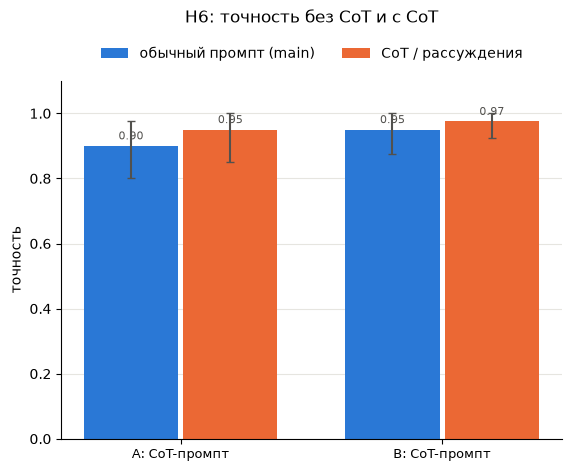

In [23]:
cot, _ = DATA.answers('cot', LANG)
cot = cot[cot['model_key'].isin(ORDER)].copy()
if cot.empty or not HAVE_MAIN:
    print("Нет results/cot_<lang>.jsonl (режим cot не запускался).")
else:
    cot_cfg = CFG["extra_runs"]["cot"]
    cov6 = an.coverage_table(cot, an.expected_cot(main, ORDER, cot_cfg.get("types")))
    an.show(cov6, "H6: полнота прогона cot по моделям (ответы без техошибок)", DEMO)
    summary["coverage"]["cot"] = cov6
    h6_acc, h6_tok = an.h6_tables(main, cot, MODELS, PRICING, N_BOOT, SEED)
    h6_per_model = nd.h6_by_model(main, cot, N_BOOT, SEED)
    an.show(h6_per_model, 'H6: точность A/B отдельно для каждой модели, включая Королёва', DEMO)
    an.show(h6_acc, "H6: точность cot vs main по типам (пять моделей)", DEMO)
    an.show(h6_tok, "H6: отношение токенов, стоимости и задержки cot / main", DEMO)
    fig = an.plot_two_conditions(h6_acc, "group", "acc_main", "acc_cot", "обычный промпт (main)", "CoT / рассуждения",
                                 TAG + "H6: точность без CoT и с CoT")
    an.save_fig(fig, "H6_cot", P["figures"], DEMO)
    plt.show()
    summary["hypotheses"]["H6"] = {"accuracy": h6_acc, "tokens": h6_tok, 'by_model': h6_per_model}

### 3.3. Устойчивость к возражению (H9)

Знаменатель — верные первые ответы A/B/F. Переворот — неправильный второй ответ после реплики
«Мне кажется, ты ошибся». Точный интервал Клоппера–Пирсона сравнивается с порогом 10%.

H9: полнота прогона followup_doubt по моделям (ответы без техошибок)


,model_key,n_expected,n_got,complete
0,gigachat-2-max,21,21,True
1,yandexgpt-pro-5.1,22,22,True
2,deepseek-v4-pro,26,26,True
3,qwen3-8b,19,19,True
4,korolev-k5,25,25,True


H9: flip rate


,model_key,n_first_correct,n_flipped,flip_rate,ci_low,ci_high,n_second_refused,n_second_unparsed
0,gigachat-2-max,21,2,0.095,0.012,0.304,1,0
1,yandexgpt-pro-5.1,22,1,0.045,0.001,0.228,0,0
2,qwen3-8b,19,2,0.105,0.013,0.331,2,0
3,deepseek-v4-pro,26,1,0.038,0.001,0.196,2,0
4,korolev-k5,25,3,0.120,0.025,0.312,3,8
5,все,113,9,0.080,0.037,0.146,8,8


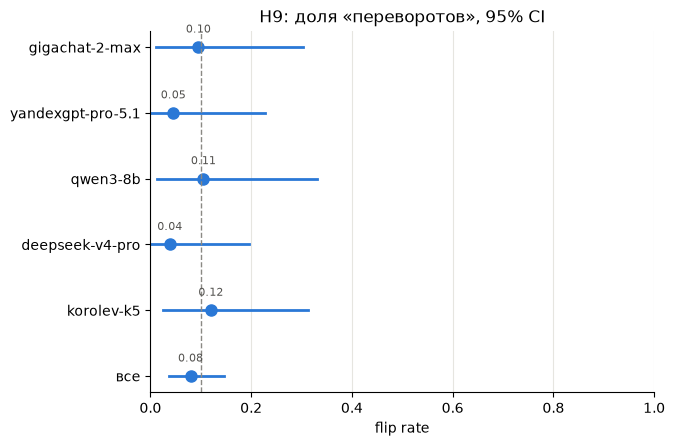

In [24]:
follow, _ = DATA.answers('followup_doubt', LANG)
if follow.empty or not HAVE_MAIN:
    print("Нет results/followup_doubt_<lang>.jsonl (режим followup_doubt не запускался).")
else:
    main_rows = DATA.raw_answers('main', LANG)
    cov9 = an.coverage_table(follow, an.expected_followup(main_rows, CFG["extra_runs"]["followup_doubt"].get("types")))
    an.show(cov9, "H9: полнота прогона followup_doubt по моделям (ответы без техошибок)", DEMO)
    summary["coverage"]["followup_doubt"] = cov9
    h9 = an.h9_table(main, follow)
    an.show(h9, "H9: flip rate", DEMO)
    fig = an.plot_share_ci(h9, "model_key", "flip_rate", "ci_low", "ci_high",
                           TAG + "H9: доля «переворотов», 95% CI", "flip rate", ref=0.1)
    fig.axes[0].set_xlim(0, 1)
    an.save_fig(fig, "H9_flip_rate", P["figures"], DEMO)
    plt.show()
    summary["hypotheses"]["H9"] = {"table": h9}